# UCI Rocket League Skillshots: Clean ML Pipeline (From Scratch)

This notebook rebuilds the project from scratch using the correct block-formatted dataset parsing logic.

## Problem
Predict the skillshot class label for each sample using a PyTorch linear classifier.

## Class labels
- -1 = noise
- 1 = ceiling shot
- 2 = power shot
- 3 = waving dash
- 5 = air dribble
- 6 = front flick
- 7 = musty flick

## 1) Imports

In [1]:
from pathlib import Path
from collections import Counter
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

import torch
import torch.nn as nn

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Imports loaded.")

Imports loaded.


## 2) Load + Parse Raw Block-Formatted Dataset

Dataset parsing logic:
- First line = 18 feature names
- Single-token lines in {-1, 1, 2, 3, 5, 6, 7} are class labels
- All following 18-value rows belong to that sample until the next label

In [2]:
label_name_map = {
    -1: "noise",
    1: "ceiling shot",
    2: "power shot",
    3: "waving dash",
    5: "air dribble",
    6: "front flick",
    7: "musty flick",
}
valid_labels = set(label_name_map.keys())


def parse_skillshots_data(file_path: Path):
    """Parse the .data file into variable-length sequences.

    Returns:
        feature_names: list[str]
        X_sequences: list[pd.DataFrame] (one DataFrame per sample)
        y_labels: list[int]
    """
    lines = [ln.strip() for ln in file_path.read_text(encoding="utf-8", errors="replace").splitlines() if ln.strip()]
    if not lines:
        raise ValueError("Input file is empty.")

    feature_names = lines[0].split()
    if len(feature_names) != 18:
        raise ValueError(f"Expected 18 feature names in header, got {len(feature_names)}")

    X_sequences = []
    y_labels = []

    current_label = None
    current_rows = []

    def flush_current_sample():
        if current_label is None:
            return
        if len(current_rows) == 0:
            # Keep parser robust: create empty sample table if needed
            seq_df = pd.DataFrame(columns=feature_names)
        else:
            seq_df = pd.DataFrame(current_rows, columns=feature_names)
        X_sequences.append(seq_df)
        y_labels.append(current_label)

    for line_no, line in enumerate(lines[1:], start=2):
        tokens = line.split()

        # Detect label-only lines
        if len(tokens) == 1:
            try:
                maybe_label = int(tokens[0])
            except ValueError:
                maybe_label = None

            if maybe_label in valid_labels:
                flush_current_sample()
                current_label = maybe_label
                current_rows = []
                continue

        # Otherwise this should be a numeric row with 18 values
        if len(tokens) != 18:
            raise ValueError(
                f"Line {line_no}: expected 18 numeric values or a single label. Got {len(tokens)} token(s)."
            )

        if current_label is None:
            raise ValueError(f"Line {line_no}: found feature row before first label line.")

        try:
            row_values = [float(tok) for tok in tokens]
        except ValueError as exc:
            raise ValueError(f"Line {line_no}: non-numeric value found in feature row.") from exc

        current_rows.append(row_values)

    # Flush final sample
    flush_current_sample()

    return feature_names, X_sequences, y_labels


def engineer_sample_features(seq_df: pd.DataFrame, feature_names: list[str]):
    """Convert one variable-length sample into one fixed-length feature row.

    Required features:
    - For each of 18 columns: mean, std, min, max
    - For binary columns: sum
    - duration = max(Time)
    """
    row = {}

    # Determine binary columns from known control features if present
    expected_binary_cols = ["up", "accelerate", "slow", "goal", "left", "boost", "camera", "down", "right", "slide", "jump"]
    binary_cols = [c for c in expected_binary_cols if c in feature_names]

    for col in feature_names:
        if len(seq_df) == 0:
            row[f"{col}_mean"] = 0.0
            row[f"{col}_std"] = 0.0
            row[f"{col}_min"] = 0.0
            row[f"{col}_max"] = 0.0
        else:
            series = seq_df[col]
            row[f"{col}_mean"] = float(series.mean())
            row[f"{col}_std"] = float(series.std(ddof=0))
            row[f"{col}_min"] = float(series.min())
            row[f"{col}_max"] = float(series.max())

    # Sum only for binary columns
    for col in binary_cols:
        row[f"{col}_sum"] = float(seq_df[col].sum()) if len(seq_df) else 0.0

    # Duration feature from Time
    if "Time" in seq_df.columns and len(seq_df):
        row["duration"] = float(seq_df["Time"].max())
    else:
        row["duration"] = 0.0

    return row

## 3) Build One Row Per Sample (Engineered Feature Table)

In [5]:
data_path = Path("data/rocket_league_skillshots.data")
assert data_path.exists(), f"Dataset not found at {data_path.resolve()}"

feature_names, X_sequences, y_labels = parse_skillshots_data(data_path)

engineered_rows = []
for seq_df, label in zip(X_sequences, y_labels):
    feat_row = engineer_sample_features(seq_df, feature_names)
    feat_row["label"] = label
    feat_row["class_name"] = label_name_map[label]
    engineered_rows.append(feat_row)

df = pd.DataFrame(engineered_rows).fillna(0)

# Label encoding for PyTorch CrossEntropyLoss (needs 0..num_classes-1)
sorted_labels = sorted(valid_labels)
label_to_index = {lab: idx for idx, lab in enumerate(sorted_labels)}
index_to_label = {idx: lab for lab, idx in label_to_index.items()}
index_to_name = {idx: label_name_map[lab] for idx, lab in index_to_label.items()}
df["target"] = df["label"].map(label_to_index)

print("Parsing + feature engineering complete.")
print("Number of samples:", len(df))
print("Number of engineered columns:", df.shape[1])
display(df.head())

Parsing + feature engineering complete.
Number of samples: 298
Number of engineered columns: 87


,BallAcceleration_mean,BallAcceleration_std,BallAcceleration_min,BallAcceleration_max,Time_mean,Time_std,Time_min,Time_max,DistanceWall_mean,DistanceWall_std,...,boost_sum,camera_sum,down_sum,right_sum,slide_sum,jump_sum,duration,label,class_name,target
0,-3853.867885,35118.068950,-195896.923082,33405.144871,2.326591,1.464055,0.0,5.070104,3770.785313,172.166242,...,7.0,2.0,0.0,26.0,7.0,9.0,5.070104,6,front flick,5
1,-848.813985,24746.867916,-57692.175539,127059.240710,3.261104,2.439726,0.0,8.161284,1698.631795,1389.537152,...,8.0,4.0,0.0,39.0,18.0,10.0,8.161284,-1,noise,0
2,-1264.766385,27831.333948,-89020.813365,124246.293754,3.453076,2.821939,0.0,8.130110,1796.122941,1496.993284,...,10.0,3.0,0.0,34.0,4.0,7.0,8.130110,-1,noise,0
3,-2133.341430,9238.505488,-39930.029136,8232.787624,1.612082,0.898798,0.0,3.610510,1072.541739,950.041522,...,7.0,3.0,0.0,23.0,8.0,11.0,3.610510,-1,noise,0
4,-7148.505767,30389.928898,-141736.497607,5120.925237,1.311509,1.027101,0.0,3.681763,3800.485000,121.139418,...,8.0,3.0,0.0,16.0,7.0,5.0,3.681763,-1,noise,0


## 4) Exploratory Data Analysis (EDA)

Required EDA outputs:
- shape
- class counts
- class distribution chart
- correlation heatmap
- summary statistics

DataFrame shape: (298, 87)

Class counts:
label
-1    43
 1    30
 2    60
 3    38
 5    45
 6    46
 7    36
Name: count, dtype: int64


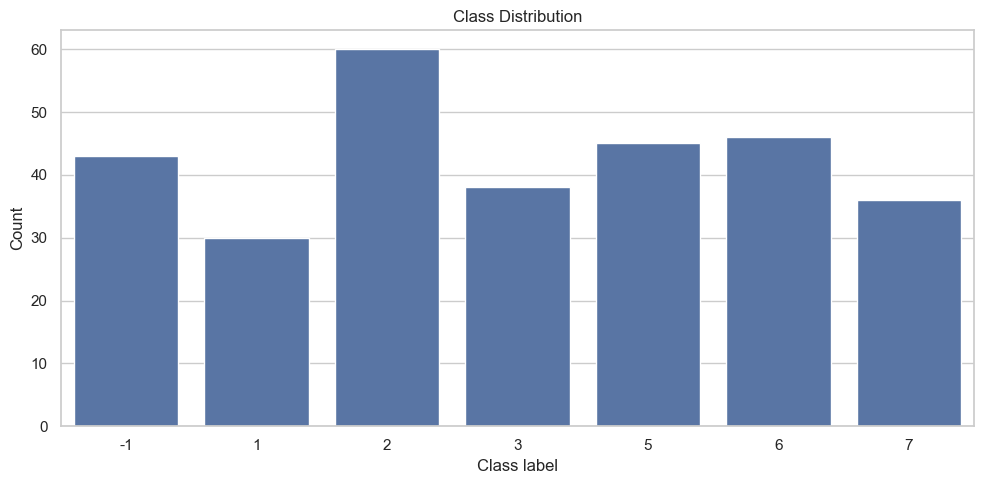

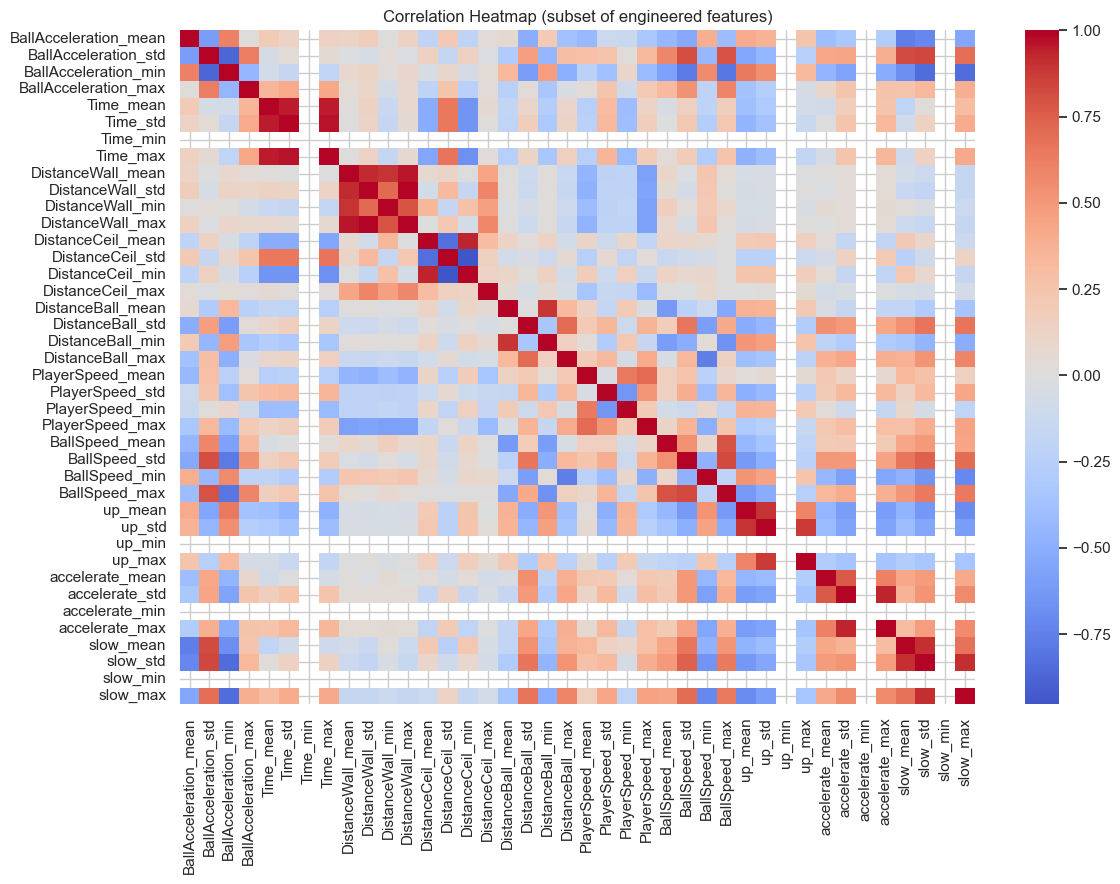


Summary statistics (engineered numeric features):


,count,mean,std,min,25%,50%,75%,max
BallAcceleration_mean,298.0,-4452.819314,4767.413370,-26128.652035,-6807.479333,-4064.452173,-1295.464847,11599.404268
BallAcceleration_std,298.0,43621.078710,23972.934834,0.000000,30394.731380,44994.344267,57678.024484,128138.569297
BallAcceleration_min,298.0,-167618.336802,90681.419594,-319123.135620,-237844.542688,-197851.574354,-97460.810220,0.000000
BallAcceleration_max,298.0,82996.139742,59445.231511,-32.246237,33487.893925,78800.817451,120773.871300,294344.739285
Time_mean,298.0,1.793712,0.817357,0.382722,1.182718,1.649256,2.284645,6.182901
...,...,...,...,...,...,...,...,...
down_sum,298.0,0.238255,1.038135,0.000000,0.000000,0.000000,0.000000,9.000000
right_sum,298.0,21.302013,10.835597,2.000000,13.000000,19.000000,28.000000,59.000000
slide_sum,298.0,6.154362,4.442259,0.000000,3.000000,6.000000,9.000000,24.000000
jump_sum,298.0,9.436242,6.683133,0.000000,4.000000,9.000000,13.000000,37.000000


In [6]:
print("DataFrame shape:", df.shape)
print("\nClass counts:")
print(df["label"].value_counts().sort_index())

plt.figure(figsize=(10, 5))
order = sorted(df["label"].unique())
sns.countplot(data=df, x="label", order=order)
plt.title("Class Distribution")
plt.xlabel("Class label")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# Correlation heatmap on first 40 numeric columns for readability
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
exclude_cols = ["label", "target"]
numeric_feature_cols = [c for c in numeric_cols if c not in exclude_cols]
heatmap_cols = numeric_feature_cols[:40]

corr = df[heatmap_cols].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (subset of engineered features)")
plt.tight_layout()
plt.show()

print("\nSummary statistics (engineered numeric features):")
display(df[numeric_feature_cols].describe().T)

## 5) Preprocessing

- Separate X and y
- Train/test split
- StandardScaler on X

In [7]:
X = df[numeric_feature_cols].values
y = df["target"].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=SEED,
    stratify=y,
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert to PyTorch tensors
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)

print("Train X shape:", X_train_t.shape)
print("Test X shape:", X_test_t.shape)
print("Number of classes:", len(sorted_labels))

Train X shape: torch.Size([223, 84])
Test X shape: torch.Size([75, 84])
Number of classes: 7


## 6) PyTorch Linear Classifier

Model:
- nn.Linear(input_dim, num_classes)

Loss and optimizer:
- CrossEntropyLoss
- Adam

Epoch 001/120 | Train Loss: 1.9830 | Test Accuracy: 0.3067
Epoch 020/120 | Train Loss: 0.5149 | Test Accuracy: 0.8133
Epoch 040/120 | Train Loss: 0.3155 | Test Accuracy: 0.8133
Epoch 060/120 | Train Loss: 0.2380 | Test Accuracy: 0.8267
Epoch 080/120 | Train Loss: 0.1920 | Test Accuracy: 0.8400
Epoch 100/120 | Train Loss: 0.1599 | Test Accuracy: 0.8533
Epoch 120/120 | Train Loss: 0.1360 | Test Accuracy: 0.8533


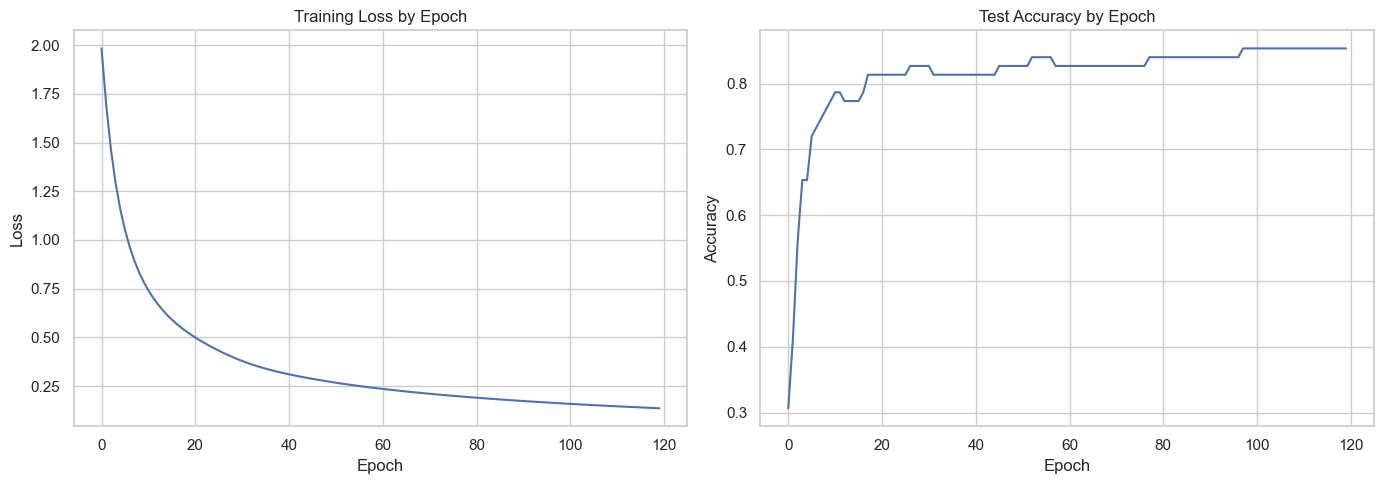

In [8]:
class LinearClassifier(nn.Module):
    def __init__(self, input_dim: int, num_classes: int):
        super().__init__()
        self.linear = nn.Linear(input_dim, num_classes)

    def forward(self, x):
        return self.linear(x)


input_dim = X_train_t.shape[1]
num_classes = len(sorted_labels)
model = LinearClassifier(input_dim, num_classes)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

epochs = 120
train_losses = []
test_accuracies = []

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()

    logits = model(X_train_t)
    loss = criterion(logits, y_train_t)
    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    model.eval()
    with torch.no_grad():
        test_logits = model(X_test_t)
        y_pred_epoch = torch.argmax(test_logits, dim=1)
        test_acc = (y_pred_epoch == y_test_t).float().mean().item()
    test_accuracies.append(test_acc)

    if (epoch + 1) % 20 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:03d}/{epochs} | Train Loss: {loss.item():.4f} | Test Accuracy: {test_acc:.4f}")

# Plot training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(train_losses)
axes[0].set_title("Training Loss by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

axes[1].plot(test_accuracies)
axes[1].set_title("Test Accuracy by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")

plt.tight_layout()
plt.show()

## 7) Evaluation

Required outputs:
- final accuracy
- precision
- recall
- F1 score
- confusion matrix

Final Evaluation Metrics
Accuracy : 0.8533
Precision: 0.8641
Recall   : 0.8533
F1 score : 0.8541

Classification report:
              precision    recall  f1-score   support

       noise       0.69      0.82      0.75        11
ceiling shot       1.00      0.71      0.83         7
  power shot       0.93      0.93      0.93        15
 waving dash       0.91      1.00      0.95        10
 air dribble       0.91      0.91      0.91        11
 front flick       0.90      0.75      0.82        12
 musty flick       0.70      0.78      0.74         9

    accuracy                           0.85        75
   macro avg       0.86      0.84      0.85        75
weighted avg       0.86      0.85      0.85        75



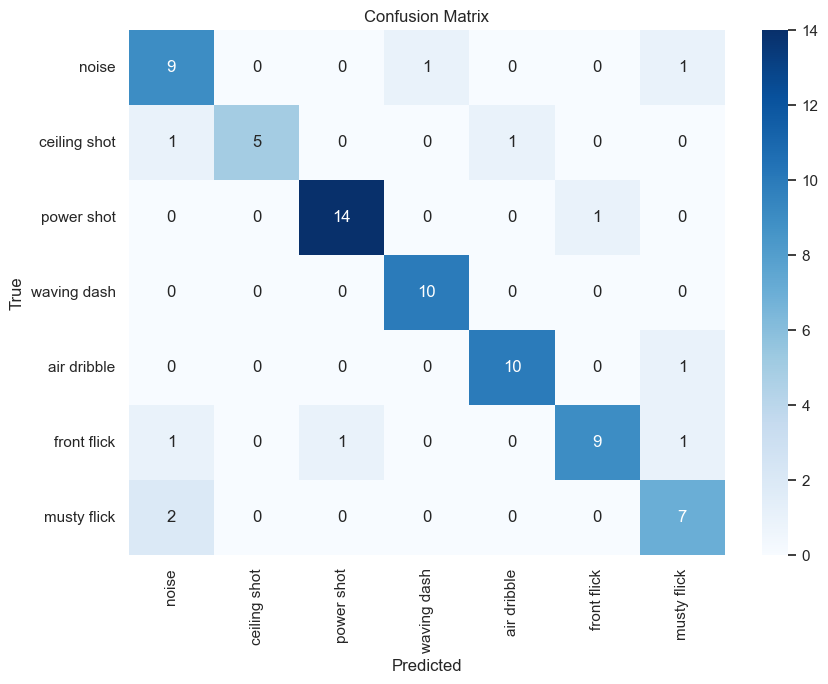

In [9]:
model.eval()
with torch.no_grad():
    final_logits = model(X_test_t)
    y_pred = torch.argmax(final_logits, dim=1).cpu().numpy()

y_true = y_test_t.cpu().numpy()

final_accuracy = accuracy_score(y_true, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0,
)

print("Final Evaluation Metrics")
print(f"Accuracy : {final_accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 score : {f1:.4f}")

ordered_idx = sorted(index_to_name.keys())
ordered_names = [index_to_name[i] for i in ordered_idx]

print("\nClassification report:")
print(classification_report(y_true, y_pred, target_names=ordered_names, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=ordered_idx)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=ordered_names, yticklabels=ordered_names)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

## 8) Interpretation

This section highlights which classes performed best and worst, and gives likely reasons.

In [10]:
# Use class-specific recall from classification report to identify easiest/hardest classes
report_dict = classification_report(y_true, y_pred, target_names=ordered_names, output_dict=True, zero_division=0)

class_recalls = {}
for class_name in ordered_names:
    class_recalls[class_name] = report_dict[class_name]["recall"]

best_classes = sorted(class_recalls.items(), key=lambda x: x[1], reverse=True)[:2]
hardest_classes = sorted(class_recalls.items(), key=lambda x: x[1])[:2]

print("Best performing classes (highest recall):")
for c, r in best_classes:
    print(f"- {c}: recall={r:.3f}")

print("\nHardest classes to classify (lowest recall):")
for c, r in hardest_classes:
    print(f"- {c}: recall={r:.3f}")

print("\nPossible reasons:")
print("- Some classes may have fewer samples (class imbalance).")
print("- A single linear layer may not capture complex nonlinear motion patterns.")
print("- Some skillshots can have overlapping summary statistics, causing confusion.")

Best performing classes (highest recall):
- waving dash: recall=1.000
- power shot: recall=0.933

Hardest classes to classify (lowest recall):
- ceiling shot: recall=0.714
- front flick: recall=0.750

Possible reasons:
- Some classes may have fewer samples (class imbalance).
- A single linear layer may not capture complex nonlinear motion patterns.
- Some skillshots can have overlapping summary statistics, causing confusion.
